# 10 — VisionStudio Integrated Demo

## التجربة الموحدة لمشروع معالجة الصور والرؤية الحاسوبية

هذا الدفتر يجمع أهم الوظائف التي طبقناها في الدفاتر السابقة داخل مسار واحد:

```text
صورة أو إطار فيديو
→ تحويلات وتحسينات وفلاتر
→ حواف / Threshold / Morphology
→ كشف الوجه والعين
→ كشف الأجسام بـ YOLO26n
→ عرض وحفظ النتائج والتقرير
```

يمثل هذا الدفتر نموذجًا تجريبيًا قبل نقل المنطق نفسه إلى تطبيق Android APK يعمل دون إنترنت.


## ما الذي يدمجه الدفتر؟

| الوظيفة | الدفاتر السابقة | دورها في التجربة الموحدة |
|---|---|---|
| قراءة الصور وحفظ النتائج | 01 | إدخال وإخراج موحدان |
| قص / تدوير / تغيير حجم | 02 | تحرير الصورة |
| فلاتر وتحسين وتباين وGamma | 03 | تحسين الصورة |
| حواف وThreshold | 04 | تحليل التفاصيل والحواف |
| Morphology | 05 | تنقية أو إبراز البنية |
| فيديو | 06 | معالجة إطارًا بإطار |
| كاميرا مباشرة | 07 | صور الكاميرا المحفوظة في Input |
| وجه وعين | 08 | كشف Haar محلي |
| أجسام | 09 | YOLO26n محلي |

### قواعد مهمة للمشروع

- لا يعتمد الدفتر على رفع متكرر: استخدم ملفات `02_Data` الموجودة في Google Drive.
- لا ينزل نموذج YOLO مرة أخرى: يستخدم `03_Models/YOLO/yolo26n.pt` المحفوظ سابقًا.
- ملفات Android Offline الجاهزة تبقى في `03_Models/LiteRT`.
- تفعيل الفيديو أو المحرر التفاعلي اختياري، لأنهما أثقل من معالجة صورة واحدة.


## 1. إعداد الحزم وتوافق OpenCV

يحتاج كشف الوجه والعين إلى `cv2.CascadeClassifier`. إن ظهرت القيمة `False` بعد خلية الاستيراد، فعّل إصلاح OpenCV مرة واحدة، ثم أعد تشغيل جلسة Colab.

لا تفعّل تثبيت Ultralytics عادةً؛ لقد ثبّتناه في الدفتر 09. استخدمه فقط في جلسة جديدة لا تحتوي على المكتبة.


In [1]:
import subprocess
import sys

SETUP_ENVIRONMENT = False

if SETUP_ENVIRONMENT:
    # تثبيت مكتبة YOLO
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--quiet", "--upgrade", "ultralytics"
    ])

    # إزالة أي إصدار متعارض من OpenCV
    subprocess.run([
        sys.executable, "-m", "pip", "uninstall", "-y",
        "opencv-python",
        "opencv-python-headless",
        "opencv-contrib-python",
        "opencv-contrib-python-headless"
    ], check=False)

    # تثبيت إصدار يدعم Haar Cascade
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--quiet", "--no-cache-dir", "--no-deps",
        "opencv-python-headless==4.10.0.84"
    ])

    raise SystemExit(
        "تم تجهيز Ultralytics وOpenCV 4.10. "
        "اختر Restart session فقط، ثم اجعل "
        "SETUP_ENVIRONMENT = False."
    )

print("Environment is ready.")

Environment is ready.


## 2. الاستيراد وربط Google Drive


In [2]:
from pathlib import Path
from datetime import datetime
import csv
import json
import shutil
import subprocess
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import torch
    from ultralytics import YOLO
    ULTRALYTICS_READY = True
except ImportError:
    ULTRALYTICS_READY = False
    torch = None
    YOLO = None

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

IMAGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
HAAR_MODELS_DIR = PROJECT_ROOT / '03_Models/Haar_Cascades'
YOLO_MODELS_DIR = PROJECT_ROOT / '03_Models/YOLO'
LITERT_MODELS_DIR = PROJECT_ROOT / '03_Models/LiteRT'
IMAGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/10_Integrated_Demo'
)
VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/10_Integrated_Demo'
)

for directory in [
    IMAGE_INPUT_DIR,
    VIDEO_INPUT_DIR,
    HAAR_MODELS_DIR,
    YOLO_MODELS_DIR,
    LITERT_MODELS_DIR,
    IMAGE_OUTPUT_DIR,
    VIDEO_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = (
    0
    if ULTRALYTICS_READY and torch.cuda.is_available()
    else 'cpu'
)
HAAR_SUPPORTED = hasattr(cv2, 'CascadeClassifier')

print('Running in Colab:', IN_COLAB)
print('OpenCV:', cv2.__version__)
print('CascadeClassifier available:', HAAR_SUPPORTED)
print('Ultralytics available:', ULTRALYTICS_READY)
print('YOLO device:', DEVICE)
print('Project root:', PROJECT_ROOT)
print('Image input:', IMAGE_INPUT_DIR)
print('Video input:', VIDEO_INPUT_DIR)

if not HAAR_SUPPORTED:
    print(
        '\nتنبيه: كشف الوجه والعين معطل في هذه الجلسة. '
        'فعّل FIX_OPENCV_FOR_HAAR في خلية الإعداد، نفّذها مرة، '
        'ثم أعد تشغيل الجلسة.'
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
OpenCV: 4.10.0
CascadeClassifier available: True
Ultralytics available: True
YOLO device: 0
Project root: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing
Image input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Video input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input


## 3. تجهيز Haar Cascade والنموذج المحلي YOLO26n

لا يُنزّل هذا الدفتر نموذجًا جديدًا. يجب أن تكون الملفات التالية موجودة من الدفترين 08 و09:

```text
03_Models/Haar_Cascades/haarcascade_frontalface_default.xml
03_Models/Haar_Cascades/haarcascade_eye.xml
03_Models/YOLO/yolo26n.pt
03_Models/LiteRT/yolo26n_fp32.tflite
```


In [3]:
FACE_CASCADE_NAME = 'haarcascade_frontalface_default.xml'
EYE_CASCADE_NAME = 'haarcascade_eye.xml'
YOLO_MODEL_PATH = YOLO_MODELS_DIR / 'yolo26n.pt'
TFLITE_MODEL_PATH = LITERT_MODELS_DIR / 'yolo26n_fp32.tflite'
TFLITE_LABELS_PATH = LITERT_MODELS_DIR / 'coco_labels.txt'
TFLITE_METADATA_PATH = LITERT_MODELS_DIR / 'yolo26n_metadata.json'


def prepare_haar_cascade(cascade_name):
    destination = HAAR_MODELS_DIR / cascade_name
    if destination.exists():
        return destination

    source = Path(cv2.data.haarcascades) / cascade_name
    if source.exists():
        shutil.copy2(source, destination)
        return destination

    raise FileNotFoundError(
        f'ملف Haar غير موجود: {cascade_name}'
    )


face_cascade = None
eye_cascade = None

if HAAR_SUPPORTED:
    face_path = prepare_haar_cascade(FACE_CASCADE_NAME)
    eye_path = prepare_haar_cascade(EYE_CASCADE_NAME)
    face_cascade = cv2.CascadeClassifier(str(face_path))
    eye_cascade = cv2.CascadeClassifier(str(eye_path))

    if face_cascade.empty() or eye_cascade.empty():
        raise RuntimeError('فشل تحميل نموذج Haar للوجه أو العين.')

    print('Haar models ready.')
else:
    print('Haar models skipped بسبب إصدار OpenCV الحالي.')

yolo_model = None
LOAD_LOCAL_YOLO = True

if LOAD_LOCAL_YOLO:
    if not ULTRALYTICS_READY:
        raise ImportError(
            'Ultralytics غير متاحة. عُد إلى خلية الإعداد '
            'وفعّل INSTALL_ULTRALYTICS_IF_MISSING.'
        )
    if not YOLO_MODEL_PATH.exists():
        raise FileNotFoundError(
            f'لم يُعثر على النموذج المحلي: {YOLO_MODEL_PATH}. '
            'نفّذ الدفتر 09 أولًا.'
        )

    yolo_model = YOLO(str(YOLO_MODEL_PATH))
    print('YOLO model loaded from Drive:', YOLO_MODEL_PATH.name)

print('\nAndroid offline assets:')
for asset in [
    TFLITE_MODEL_PATH,
    TFLITE_LABELS_PATH,
    TFLITE_METADATA_PATH
]:
    print(('✓' if asset.exists() else '✗'), asset.name)

Haar models ready.
YOLO model loaded from Drive: yolo26n.pt

Android offline assets:
✓ yolo26n_fp32.tflite
✓ coco_labels.txt
✓ yolo26n_metadata.json


## 4. دوال أساسية للعرض والتحويل


In [5]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_results(images, columns=2, figure_width=15):
    items = list(images.items())
    rows = max(1, int(np.ceil(len(items) / columns)))
    figure, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.8),
        squeeze=False
    )

    for axis, (title, image) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(image),
            cmap='gray' if image.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def resize_max_width(image, maximum_width=1280):
    height, width = image.shape[:2]
    if maximum_width is None or width <= int(maximum_width):
        return image

    scale = int(maximum_width) / width
    return cv2.resize(
        image,
        (int(maximum_width), max(1, int(round(height * scale)))),
        interpolation=cv2.INTER_AREA
    )


def rotate_image(image, angle):
    if abs(float(angle)) < 0.001:
        return image.copy()

    height, width = image.shape[:2]
    matrix = cv2.getRotationMatrix2D(
        (width / 2, height / 2),
        float(angle),
        1.0
    )
    return cv2.warpAffine(
        image, matrix, (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )


def crop_by_percent(
    image,
    top_percent=0,
    bottom_percent=0,
    left_percent=0,
    right_percent=0
):
    height, width = image.shape[:2]
    top = int(height * max(0, min(90, top_percent)) / 100)
    bottom = int(height * max(0, min(90, bottom_percent)) / 100)
    left = int(width * max(0, min(90, left_percent)) / 100)
    right = int(width * max(0, min(90, right_percent)) / 100)

    if top + bottom >= height - 2 or left + right >= width - 2:
        raise ValueError('إعدادات القص كبيرة جدًا.')

    return image[top:height - bottom, left:width - right].copy()


def apply_filter(image, filter_name='none', kernel_size=5):
    kernel_size = max(3, int(kernel_size))
    if kernel_size % 2 == 0:
        kernel_size += 1

    if filter_name == 'average':
        return cv2.blur(image, (kernel_size, kernel_size))
    if filter_name == 'gaussian':
        return cv2.GaussianBlur(image, (kernel_size, kernel_size), 0)
    if filter_name == 'median':
        return cv2.medianBlur(image, kernel_size)
    if filter_name == 'bilateral':
        return cv2.bilateralFilter(image, 9, 75, 75)
    if filter_name == 'sharpen':
        sharpen_kernel = np.array([
            [0, -1, 0],
            [-1, 5, -1],
            [0, -1, 0]
        ], dtype=np.float32)
        return cv2.filter2D(image, -1, sharpen_kernel)
    return image.copy()


def gamma_correction(image, gamma=1.0):
    gamma = max(0.1, float(gamma))
    lookup = np.array([
        ((value / 255.0) ** (1.0 / gamma)) * 255
        for value in np.arange(256)
    ]).astype(np.uint8)
    return cv2.LUT(image, lookup)


def equalize_color_histogram(image):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    lightness, channel_a, channel_b = cv2.split(lab)
    lightness = cv2.equalizeHist(lightness)
    merged = cv2.merge((lightness, channel_a, channel_b))
    return cv2.cvtColor(merged, cv2.COLOR_LAB2BGR)


def apply_morphology(image, operation='none', kernel_size=3):
    if operation == 'none':
        return image.copy()

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    kernel_size = max(3, int(kernel_size))
    if kernel_size % 2 == 0:
        kernel_size += 1
    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (kernel_size, kernel_size)
    )

    operation_map = {
        'open': cv2.MORPH_OPEN,
        'close': cv2.MORPH_CLOSE,
        'gradient': cv2.MORPH_GRADIENT,
        'tophat': cv2.MORPH_TOPHAT,
        'blackhat': cv2.MORPH_BLACKHAT
    }

    if operation not in operation_map:
        return image.copy()

    morph = cv2.morphologyEx(
        gray, operation_map[operation], kernel
    )
    return cv2.cvtColor(morph, cv2.COLOR_GRAY2BGR)

## 5. كشف الوجه والعين وكشف الأجسام

يتم كشف الوجه والعين محليًا بواسطة Haar Cascade، بينما `YOLO26n` يكتشف الأجسام العامة مثل الشخص والقطة والكلب والسيارة والكرسي.


In [6]:
def detect_faces_and_eyes(
    image,
    enabled=True,
    face_scale_factor=1.2,
    face_min_neighbors=5,
    eye_min_neighbors=5
):
    if (
        not enabled
        or face_cascade is None
        or eye_cascade is None
    ):
        return [], []

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    equalized = cv2.equalizeHist(gray)
    faces = face_cascade.detectMultiScale(
        equalized,
        scaleFactor=max(1.01, float(face_scale_factor)),
        minNeighbors=max(1, int(face_min_neighbors)),
        minSize=(30, 30),
        flags=cv2.CASCADE_SCALE_IMAGE
    )

    face_rows = []
    eye_rows = []

    for face_id, (x, y, width, height) in enumerate(faces, start=1):
        x, y, width, height = map(int, (x, y, width, height))
        face_rows.append({
            'face_id': face_id,
            'x': x, 'y': y,
            'width': width, 'height': height
        })

        upper_height = max(1, int(height * 0.65))
        eye_region = equalized[y:y + upper_height, x:x + width]
        eyes = eye_cascade.detectMultiScale(
            eye_region,
            scaleFactor=1.15,
            minNeighbors=max(1, int(eye_min_neighbors)),
            minSize=(8, 8),
            flags=cv2.CASCADE_SCALE_IMAGE
        )

        largest_eyes = sorted(
            eyes,
            key=lambda eye: int(eye[2]) * int(eye[3]),
            reverse=True
        )[:2]

        for eye_id, (ex, ey, ew, eh) in enumerate(
            largest_eyes,
            start=1
        ):
            eye_rows.append({
                'face_id': face_id,
                'eye_id': eye_id,
                'x': x + int(ex),
                'y': y + int(ey),
                'width': int(ew),
                'height': int(eh)
            })

    return face_rows, eye_rows


def draw_face_eye_detections(image, face_rows, eye_rows):
    result = image.copy()

    for face in face_rows:
        x, y = face['x'], face['y']
        width, height = face['width'], face['height']
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (0, 220, 0), 2
        )
        cv2.putText(
            result, 'Face', (x, max(20, y - 7)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6,
            (0, 220, 0), 2, cv2.LINE_AA
        )

    for eye in eye_rows:
        x, y = eye['x'], eye['y']
        width, height = eye['width'], eye['height']
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (0, 255, 255), 2
        )

    return result


def yolo_detection_rows(
    image,
    enabled=True,
    confidence=0.25,
    iou=0.70,
    image_size=640
):
    if not enabled:
        return []
    if yolo_model is None:
        raise RuntimeError('YOLO model غير محمّل.')

    prediction = yolo_model.predict(
        source=image,
        conf=float(confidence),
        iou=float(iou),
        imgsz=int(image_size),
        device=DEVICE,
        verbose=False
    )[0]

    if prediction.boxes is None:
        return []

    xyxy_values = prediction.boxes.xyxy.detach().cpu().numpy()
    confidence_values = prediction.boxes.conf.detach().cpu().numpy()
    class_values = prediction.boxes.cls.detach().cpu().numpy().astype(int)

    rows = []
    for detection_id, (box, score, class_id) in enumerate(
        zip(xyxy_values, confidence_values, class_values),
        start=1
    ):
        rows.append({
            'detection_id': detection_id,
            'class_id': int(class_id),
            'class_name': prediction.names[int(class_id)],
            'confidence': float(score),
            'x1': float(box[0]), 'y1': float(box[1]),
            'x2': float(box[2]), 'y2': float(box[3])
        })

    return rows


def draw_yolo_detections(image, detection_rows):
    result = image.copy()
    for row in detection_rows:
        x1, y1 = int(row['x1']), int(row['y1'])
        x2, y2 = int(row['x2']), int(row['y2'])
        label = f"{row['class_name']} {row['confidence']:.2f}"
        cv2.rectangle(
            result, (x1, y1), (x2, y2), (255, 80, 0), 2
        )
        cv2.putText(
            result, label, (x1, max(20, y1 - 7)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55,
            (255, 80, 0), 2, cv2.LINE_AA
        )
    return result

## 6. خط المعالجة الموحد

الوظيفة التالية تستقبل صورة وإعدادات، ثم تعيد جميع المراحل: الصورة بعد التحويل، الصورة المحسنة، الحواف، Threshold، والنتيجة النهائية مع الكشف.


In [8]:
def apply_integrated_pipeline(image, config):
    original = image.copy()

    transformed = rotate_image(
        original,
        config['rotation_degrees']
    )
    transformed = crop_by_percent(
        transformed,
        config['crop_top_percent'],
        config['crop_bottom_percent'],
        config['crop_left_percent'],
        config['crop_right_percent']
    )

    if float(config['resize_scale']) != 1.0:
        transformed = cv2.resize(
            transformed,
            None,
            fx=float(config['resize_scale']),
            fy=float(config['resize_scale']),
            interpolation=cv2.INTER_AREA
            if float(config['resize_scale']) < 1
            else cv2.INTER_CUBIC
        )

    filtered = apply_filter(
        transformed,
        config['filter_name'],
        config['filter_kernel_size']
    )

    enhanced = cv2.convertScaleAbs(
        filtered,
        alpha=float(config['contrast']),
        beta=int(config['brightness'])
    )
    enhanced = gamma_correction(
        enhanced, config['gamma']
    )

    if config['equalize_histogram']:
        enhanced = equalize_color_histogram(enhanced)

    morphology = apply_morphology(
        enhanced,
        config['morphology_operation'],
        config['morphology_kernel_size']
    )

    gray = cv2.cvtColor(enhanced, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(
        gray,
        int(config['canny_low_threshold']),
        int(config['canny_high_threshold'])
    )

    if config['threshold_mode'] == 'binary':
        _, threshold = cv2.threshold(
            gray, int(config['binary_threshold']),
            255, cv2.THRESH_BINARY
        )
    elif config['threshold_mode'] == 'otsu':
        _, threshold = cv2.threshold(
            gray, 0, 255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )
    elif config['threshold_mode'] == 'adaptive':
        threshold = cv2.adaptiveThreshold(
            gray, 255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            11, 2
        )
    else:
        threshold = gray.copy()

    face_rows, eye_rows = detect_faces_and_eyes(
        enhanced,
        enabled=config['enable_face_eye']
    )
    yolo_rows = yolo_detection_rows(
        enhanced,
        enabled=config['enable_yolo'],
        confidence=config['yolo_confidence'],
        iou=config['yolo_iou'],
        image_size=config['yolo_image_size']
    )

    annotated = enhanced.copy()
    annotated = draw_yolo_detections(annotated, yolo_rows)
    annotated = draw_face_eye_detections(
        annotated, face_rows, eye_rows
    )

    return {
        'original': original,
        'transformed': transformed,
        'filtered': filtered,
        'enhanced': enhanced,
        'morphology': morphology,
        'gray': gray,
        'edges': edges,
        'threshold': threshold,
        'annotated': annotated,
        'face_rows': face_rows,
        'eye_rows': eye_rows,
        'yolo_rows': yolo_rows
    }

## 7. إدخال الصورة واختيارها

الافتراضي هو عدم رفع ملف جديد. صور الكاميرا التي التقطتها في الدفتر 07 موجودة أصلًا في المجلد نفسه ويمكن اختيارها بالاسم.


In [9]:
UPLOAD_NEW_IMAGE = False
SUPPORTED_IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.tif', '.tiff'
}
LAST_UPLOADED_IMAGE_NAME = ''

if IN_COLAB and UPLOAD_NEW_IMAGE:
    from google.colab import files

    uploaded = files.upload()
    for file_name, file_data in uploaded.items():
        safe_name = Path(file_name).name
        extension = Path(safe_name).suffix.lower()
        if extension not in SUPPORTED_IMAGE_EXTENSIONS:
            print('تم تجاهل امتداد غير مدعوم:', safe_name)
            continue

        decoded = cv2.imdecode(
            np.frombuffer(file_data, dtype=np.uint8),
            cv2.IMREAD_COLOR
        )
        if decoded is None:
            print('تم تجاهل صورة غير صالحة:', safe_name)
            continue

        destination = IMAGE_INPUT_DIR / safe_name
        cv2.imwrite(str(destination), decoded)
        LAST_UPLOADED_IMAGE_NAME = safe_name
        print('Saved:', destination)


def image_paths_in_input():
    paths = []
    for path in sorted(IMAGE_INPUT_DIR.iterdir()):
        if (
            path.is_file()
            and path.suffix.lower() in SUPPORTED_IMAGE_EXTENSIONS
            and cv2.imread(str(path), cv2.IMREAD_COLOR) is not None
        ):
            paths.append(path)
    return paths


available_image_paths = image_paths_in_input()
if not available_image_paths:
    raise ValueError('لا توجد صور صالحة في Images/Input.')

print('Available images:')
for image_path in available_image_paths:
    print('-', image_path.name)

Available images:
- R.jpeg
- balloons.jpg
- camera_photo_20260917_225311.jpg
- camera_photo_20260917_225540.jpg
- camera_photo_20260917_232608.jpg
- children (1).jpeg
- children.jpeg
- coins.jpg
- face_test_grace_hopper.jpg


Selected image: face_test_grace_hopper.jpg
Shape: (600, 512, 3)


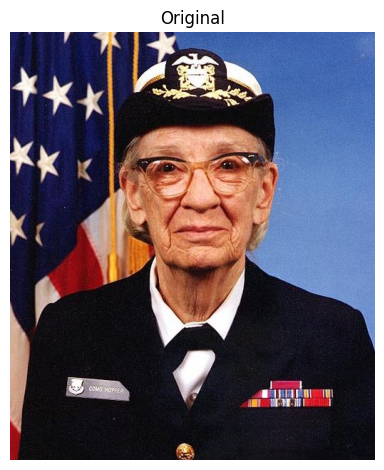

In [10]:
# اكتب اسم الصورة هنا، أو اتركه فارغًا لاختيار آخر صورة مرفوعة
# أو صورة الاختبار الموجودة في المجلد.
SELECTED_IMAGE_NAME = LAST_UPLOADED_IMAGE_NAME

image_by_name = {
    path.name: path for path in available_image_paths
}

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in image_by_name:
        raise ValueError('الصورة المطلوبة غير موجودة في Input.')
    selected_image_path = image_by_name[SELECTED_IMAGE_NAME]
elif 'face_test_grace_hopper.jpg' in image_by_name:
    selected_image_path = image_by_name['face_test_grace_hopper.jpg']
else:
    selected_image_path = available_image_paths[0]

selected_image = cv2.imread(
    str(selected_image_path), cv2.IMREAD_COLOR
)
selected_image = resize_max_width(selected_image, 1280)

print('Selected image:', selected_image_path.name)
print('Shape:', selected_image.shape)
show_results(
    {'Original': selected_image},
    columns=1,
    figure_width=8
)

## 8. إعدادات المحرر الموحد

عدّل هذه المتغيرات ثم شغّل خلية التنفيذ التالية. ابدأ بإعدادات بسيطة، وبعد ذلك جرّب الفلاتر والقص والتدوير.


In [11]:
PIPELINE_CONFIG = {
    # التحويلات
    'rotation_degrees': 0,
    'resize_scale': 1.0,
    'crop_top_percent': 0,
    'crop_bottom_percent': 0,
    'crop_left_percent': 0,
    'crop_right_percent': 0,

    # الفلاتر والتحسين
    'filter_name': 'none',
    # الخيارات: none, average, gaussian, median, bilateral, sharpen
    'filter_kernel_size': 5,
    'brightness': 0,     # من -100 إلى 100
    'contrast': 1.0,     # مثل 0.8 أو 1.2 أو 1.5
    'gamma': 1.0,        # > 1 يفتح الظلال، < 1 يغمقها
    'equalize_histogram': False,

    # morphology والحواف والـ threshold
    'morphology_operation': 'none',
    # none, open, close, gradient, tophat, blackhat
    'morphology_kernel_size': 3,
    'canny_low_threshold': 80,
    'canny_high_threshold': 160,
    'threshold_mode': 'none',
    # none, binary, otsu, adaptive
    'binary_threshold': 127,

    # الذكاء الاصطناعي
    'enable_face_eye': True,
    'enable_yolo': True,
    'yolo_confidence': 0.25,
    'yolo_iou': 0.70,
    'yolo_image_size': 640
}

print(json.dumps(PIPELINE_CONFIG, ensure_ascii=False, indent=2))

{
  "rotation_degrees": 0,
  "resize_scale": 1.0,
  "crop_top_percent": 0,
  "crop_bottom_percent": 0,
  "crop_left_percent": 0,
  "crop_right_percent": 0,
  "filter_name": "none",
  "filter_kernel_size": 5,
  "brightness": 0,
  "contrast": 1.0,
  "gamma": 1.0,
  "equalize_histogram": false,
  "morphology_operation": "none",
  "morphology_kernel_size": 3,
  "canny_low_threshold": 80,
  "canny_high_threshold": 160,
  "threshold_mode": "none",
  "binary_threshold": 127,
  "enable_face_eye": true,
  "enable_yolo": true,
  "yolo_confidence": 0.25,
  "yolo_iou": 0.7,
  "yolo_image_size": 640
}


## 9. تشغيل المحرر على الصورة وحفظ النتيجة


Integrated processing time: 7831.12 ms
Faces: 1
Eyes: 1
Objects: 2


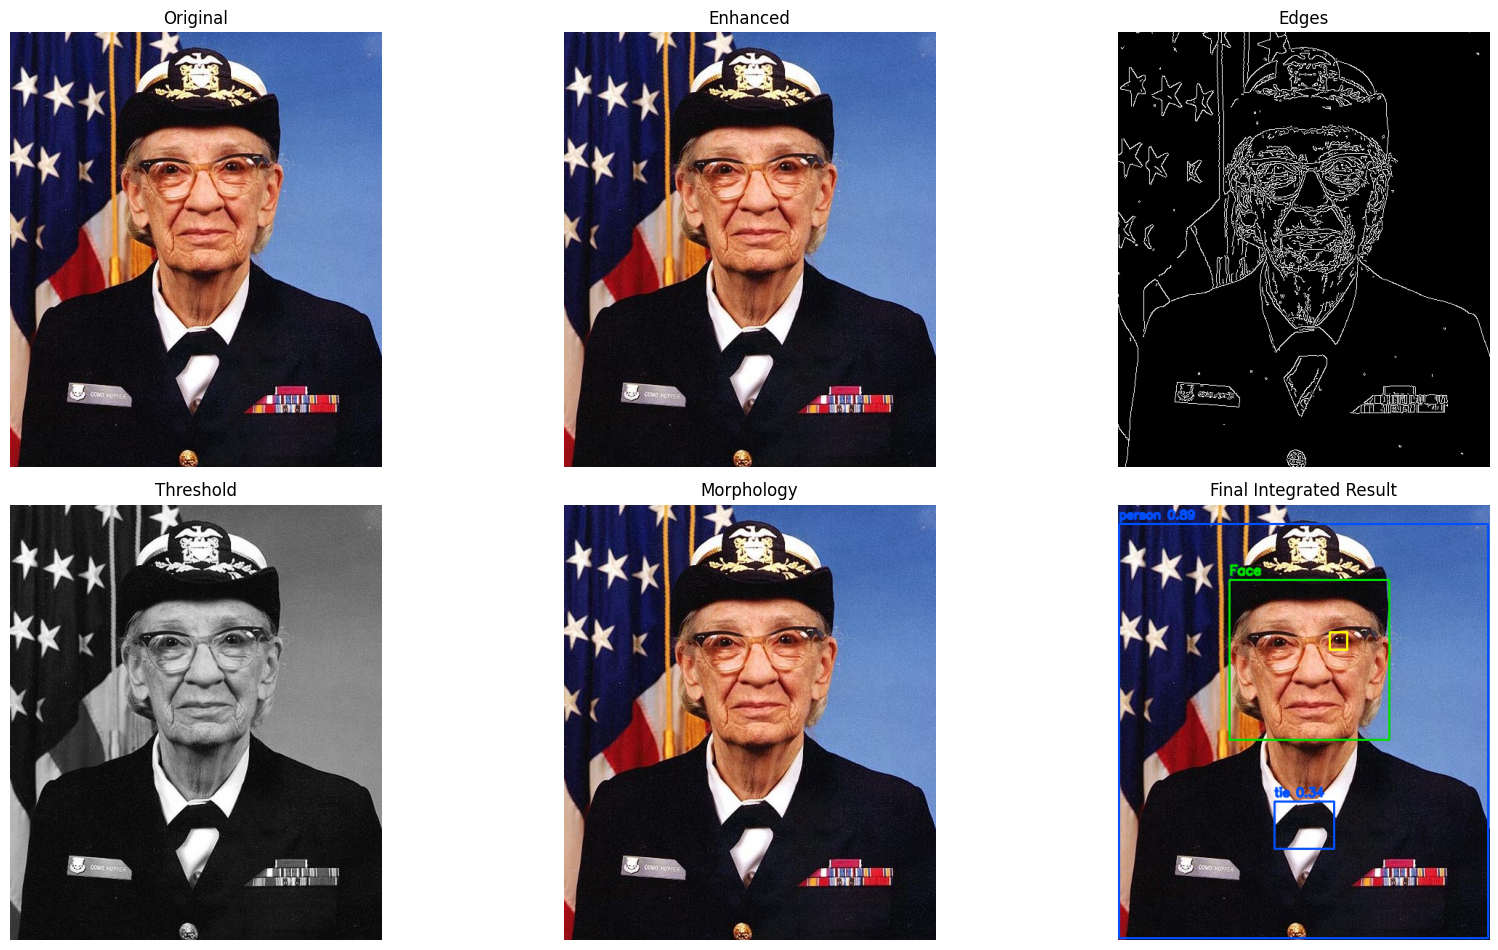

In [12]:
started = time.perf_counter()
image_result = apply_integrated_pipeline(
    selected_image,
    PIPELINE_CONFIG
)
elapsed_ms = (time.perf_counter() - started) * 1000

print(f'Integrated processing time: {elapsed_ms:.2f} ms')
print('Faces:', len(image_result['face_rows']))
print('Eyes:', len(image_result['eye_rows']))
print('Objects:', len(image_result['yolo_rows']))

show_results(
    {
        'Original': image_result['original'],
        'Enhanced': image_result['enhanced'],
        'Edges': image_result['edges'],
        'Threshold': image_result['threshold'],
        'Morphology': image_result['morphology'],
        'Final Integrated Result': image_result['annotated']
    },
    columns=3,
    figure_width=18
)

In [13]:
def safe_file_part(value):
    return ''.join(
        character if character.isalnum() else '_'
        for character in str(value)
    )


def save_integrated_image_result(result, source_path, config):
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    output_directory = IMAGE_OUTPUT_DIR / (
        f'{Path(source_path).stem}_{timestamp}'
    )
    output_directory.mkdir(parents=True, exist_ok=True)

    image_files = {
        '00_original.jpg': result['original'],
        '01_transformed.jpg': result['transformed'],
        '02_enhanced.jpg': result['enhanced'],
        '03_morphology.jpg': result['morphology'],
        '04_edges.png': result['edges'],
        '05_threshold.png': result['threshold'],
        '06_final_integrated.jpg': result['annotated']
    }

    for file_name, image in image_files.items():
        cv2.imwrite(str(output_directory / file_name), image)

    yolo_table = pd.DataFrame(result['yolo_rows'])
    face_table = pd.DataFrame(result['face_rows'])
    eye_table = pd.DataFrame(result['eye_rows'])

    yolo_table.to_csv(
        output_directory / 'yolo_detections.csv',
        index=False,
        encoding='utf-8-sig'
    )
    face_table.to_csv(
        output_directory / 'faces.csv',
        index=False,
        encoding='utf-8-sig'
    )
    eye_table.to_csv(
        output_directory / 'eyes.csv',
        index=False,
        encoding='utf-8-sig'
    )

    metadata = {
        'source_image': Path(source_path).name,
        'created_at': timestamp,
        'processing_config': config,
        'face_count': len(result['face_rows']),
        'eye_count': len(result['eye_rows']),
        'object_count': len(result['yolo_rows'])
    }
    (output_directory / 'report.json').write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding='utf-8'
    )

    source_image = result['enhanced']
    height, width = source_image.shape[:2]
    crops_directory = output_directory / 'object_crops'
    crops_directory.mkdir(exist_ok=True)

    crop_count = 0
    for row in result['yolo_rows']:
        x1 = max(0, min(width, int(row['x1'])))
        y1 = max(0, min(height, int(row['y1'])))
        x2 = max(0, min(width, int(row['x2'])))
        y2 = max(0, min(height, int(row['y2'])))
        crop = source_image[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        crop_name = (
            f"{row['detection_id']:02d}_"
            f"{safe_file_part(row['class_name'])}.jpg"
        )
        if cv2.imwrite(str(crops_directory / crop_name), crop):
            crop_count += 1

    return output_directory, crop_count


saved_image_directory, saved_crop_count = (
    save_integrated_image_result(
        image_result,
        selected_image_path,
        PIPELINE_CONFIG
    )
)

print('Saved integrated result:', saved_image_directory)
print('Saved object crops:', saved_crop_count)

Saved integrated result: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/10_Integrated_Demo/face_test_grace_hopper_20260918_013411
Saved object crops: 2


## 10. محرر تفاعلي اختياري

غيّر `ENABLE_WIDGET_EDITOR` إلى `True` للحصول على أشرطة تحكم. لن يبدأ تشغيل YOLO إلا بعد الضغط على زر **Run Editor**، لتجنب تشغيل النموذج عند كل تغيير صغير.


In [14]:
ENABLE_WIDGET_EDITOR = False

if ENABLE_WIDGET_EDITOR:
    try:
        import ipywidgets as widgets
    except ImportError:
        raise ImportError('ipywidgets غير متاحة في هذه البيئة.')

    def widget_editor(
        filter_name='none', brightness=0,
        contrast=1.0, gamma=1.0,
        rotation=0, face_eye=True, yolo=True
    ):
        widget_config = PIPELINE_CONFIG.copy()
        widget_config.update({
            'filter_name': filter_name,
            'brightness': brightness,
            'contrast': contrast,
            'gamma': gamma,
            'rotation_degrees': rotation,
            'enable_face_eye': face_eye,
            'enable_yolo': yolo
        })
        result = apply_integrated_pipeline(
            selected_image, widget_config
        )
        show_results(
            {
                'Original': result['original'],
                'Final Result': result['annotated']
            },
            columns=2,
            figure_width=14
        )
        print(
            'Faces:', len(result['face_rows']),
            '| Objects:', len(result['yolo_rows'])
        )

    widgets.interact_manual.options(
        manual_name='Run Editor'
    )(
        widget_editor,
        filter_name=widgets.Dropdown(
            options=[
                'none', 'average', 'gaussian',
                'median', 'bilateral', 'sharpen'
            ],
            value='none',
            description='Filter'
        ),
        brightness=widgets.IntSlider(
            value=0, min=-100, max=100,
            step=5, description='Brightness'
        ),
        contrast=widgets.FloatSlider(
            value=1.0, min=0.5, max=2.0,
            step=0.1, description='Contrast'
        ),
        gamma=widgets.FloatSlider(
            value=1.0, min=0.4, max=2.5,
            step=0.1, description='Gamma'
        ),
        rotation=widgets.IntSlider(
            value=0, min=-180, max=180,
            step=5, description='Rotation'
        ),
        face_eye=widgets.Checkbox(
            value=True, description='Face/Eye'
        ),
        yolo=widgets.Checkbox(
            value=True, description='YOLO'
        )
    )
else:
    print(
        'المحرر التفاعلي معطل. '
        'استخدم PIPELINE_CONFIG أو فعّل ENABLE_WIDGET_EDITOR.'
    )

المحرر التفاعلي معطل. استخدم PIPELINE_CONFIG أو فعّل ENABLE_WIDGET_EDITOR.


## 11. معالجة فيديو بالخط الموحد

المعالجة الافتراضية متوقفة. عند تفعيلها سيطبق الفلاتر والكشف على الفيديو، ويحفظ الناتج داخل مجلد الدفتر 10.

لتقليل الحمل، يمكن تشغيل YOLO كل عدة إطارات مع إعادة استخدام آخر مربعات مكتشفة بين الإطارات.


In [15]:
SUPPORTED_VIDEO_EXTENSIONS = {
    '.mp4', '.avi', '.mov', '.mkv', '.webm', '.m4v'
}


def valid_video_paths(directory):
    valid_paths = []
    for path in sorted(Path(directory).iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_VIDEO_EXTENSIONS
        ):
            continue

        capture = cv2.VideoCapture(str(path))
        success, frame = capture.read()
        capture.release()

        if success and frame is not None:
            valid_paths.append(path)
        else:
            print('تم تجاهل فيديو غير صالح:', path.name)

    return valid_paths


def process_integrated_video(
    input_path,
    output_path,
    config,
    maximum_width=640,
    maximum_seconds=10,
    yolo_every_n_frames=2
):
    capture = cv2.VideoCapture(str(input_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {input_path}')

    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if fps <= 0:
        fps = 25.0
    max_frames = (
        int(float(maximum_seconds) * fps)
        if maximum_seconds and float(maximum_seconds) > 0
        else None
    )

    success, first_frame = capture.read()
    if not success or first_frame is None:
        capture.release()
        raise ValueError('لا يحتوي الفيديو على إطار صالح.')

    first_frame = resize_max_width(first_frame, maximum_width)
    first_result = apply_integrated_pipeline(first_frame, config)
    first_output = first_result['annotated']
    output_height, output_width = first_output.shape[:2]
    output_width -= output_width % 2
    output_height -= output_height % 2
    first_output = first_output[:output_height, :output_width]

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*'mp4v'),
        fps,
        (output_width, output_height)
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError('تعذر إنشاء فيديو المخرجات.')

    writer.write(first_output)
    frame_count = 1
    object_count = len(first_result['yolo_rows'])
    face_count = len(first_result['face_rows'])
    last_yolo_rows = first_result['yolo_rows']
    started = time.perf_counter()

    while True:
        if max_frames is not None and frame_count >= max_frames:
            break

        success, frame = capture.read()
        if not success or frame is None:
            break

        frame = resize_max_width(frame, maximum_width)
        frame_config = config.copy()
        should_run_yolo = (
            config['enable_yolo']
            and frame_count % max(1, int(yolo_every_n_frames)) == 0
        )
        if config['enable_yolo'] and not should_run_yolo:
            frame_config['enable_yolo'] = False

        frame_result = apply_integrated_pipeline(frame, frame_config)

        if should_run_yolo:
            last_yolo_rows = frame_result['yolo_rows']
        elif config['enable_yolo'] and last_yolo_rows:
            frame_result['annotated'] = draw_yolo_detections(
                frame_result['annotated'], last_yolo_rows
            )

        output_frame = frame_result['annotated']
        output_frame = cv2.resize(
            output_frame,
            (output_width, output_height),
            interpolation=cv2.INTER_AREA
        )
        writer.write(output_frame)

        object_count += len(last_yolo_rows)
        face_count += len(frame_result['face_rows'])
        frame_count += 1

        if frame_count % 30 == 0:
            print('Processed frames:', frame_count)

    capture.release()
    writer.release()
    elapsed = time.perf_counter() - started

    return {
        'frames': frame_count,
        'objects': object_count,
        'faces': face_count,
        'source_fps': fps,
        'processing_fps': frame_count / elapsed if elapsed > 0 else 0
    }


def finalize_video(opencv_output, original_video, final_output):
    command = [
        'ffmpeg', '-y',
        '-i', str(opencv_output),
        '-i', str(original_video),
        '-map', '0:v:0', '-map', '1:a?',
        '-c:v', 'libx264', '-pix_fmt', 'yuv420p',
        '-c:a', 'aac', '-shortest', str(final_output)
    ]
    completed = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if completed.returncode == 0 and Path(final_output).exists():
        return True

    shutil.copy2(opencv_output, final_output)
    print('FFmpeg warning:', completed.stderr[-400:])
    return False

In [16]:
PROCESS_INTEGRATED_VIDEO = False
SELECTED_VIDEO_NAME = ''
MAX_VIDEO_SECONDS = 10
VIDEO_OUTPUT_WIDTH = 640
YOLO_EVERY_N_FRAMES = 2

available_video_paths = valid_video_paths(VIDEO_INPUT_DIR)

if PROCESS_INTEGRATED_VIDEO:
    if not available_video_paths:
        raise ValueError('لا يوجد فيديو صالح في Videos/Input.')

    videos_by_name = {
        path.name: path for path in available_video_paths
    }
    if SELECTED_VIDEO_NAME:
        if SELECTED_VIDEO_NAME not in videos_by_name:
            raise ValueError('اسم الفيديو المحدد غير موجود.')
        selected_video_path = videos_by_name[SELECTED_VIDEO_NAME]
    else:
        selected_video_path = available_video_paths[0]

    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    temporary_video_path = VIDEO_OUTPUT_DIR / (
        f'{selected_video_path.stem}_integrated_temp_{timestamp}.mp4'
    )
    final_video_path = VIDEO_OUTPUT_DIR / (
        f'{selected_video_path.stem}_integrated_{timestamp}.mp4'
    )

    video_statistics = process_integrated_video(
        selected_video_path,
        temporary_video_path,
        PIPELINE_CONFIG,
        maximum_width=VIDEO_OUTPUT_WIDTH,
        maximum_seconds=MAX_VIDEO_SECONDS,
        yolo_every_n_frames=YOLO_EVERY_N_FRAMES
    )
    browser_compatible = finalize_video(
        temporary_video_path,
        selected_video_path,
        final_video_path
    )

    print('Input:', selected_video_path)
    print('Output:', final_video_path)
    print('Frames:', video_statistics['frames'])
    print('Object detections:', video_statistics['objects'])
    print('Face detections:', video_statistics['faces'])
    print(
        'Processing FPS:',
        f"{video_statistics['processing_fps']:.2f}"
    )
    print('Browser-compatible:', browser_compatible)
else:
    print('Integrated video processing is disabled.')
    print('Valid videos found:', len(available_video_paths))

Integrated video processing is disabled.
Valid videos found: 3


## 12. ربط الكاميرا المباشرة

صور الكاميرا التي التقطتها في الدفتر 07 تُحفظ في `02_Data/Images/Input`، ولذلك يستطيع هذا الدفتر معالجتها باختيار اسمها في `SELECTED_IMAGE_NAME`.

أما في تطبيق Android، فسيكون المسار المباشر:

```text
CameraX frame
→ OpenCV filters / transforms
→ Haar Face-Eye Detector
→ LiteRT YOLO26n Detector
→ Canvas overlay
→ Save image or record video
```

لا نكرر كود JavaScript الخاص بكاميرا المتصفح هنا، لأنه قد يختلف حسب متصفح Colab؛ الدفتر 07 هو مكان اختبار الكاميرا في Colab.


## 13. خريطة النقل إلى Android Offline

| من الدفتر 10 | المقابل في تطبيق Android |
|---|---|
| `apply_integrated_pipeline` | `ImageProcessor.kt` |
| `apply_filter`, Gamma, histogram, morphology | OpenCV داخل `ImageEffects.kt` |
| `detect_faces_and_eyes` | Haar XML داخل `assets/haarcascades/` |
| `yolo_detection_rows` | `YoloLiteRtDetector.kt` |
| `yolo26n_fp32.tflite` | `app/src/main/assets/` |
| `coco_labels.txt` | `app/src/main/assets/` |
| `process_integrated_video` | CameraX + Media3 + معالجة الإطارات |
| CSV / الصور الناتجة | MediaStore أو مجلد التطبيق |

### ملفات يجب أن توجد لاحقًا داخل APK

```text
app/src/main/assets/yolo26n_fp32.tflite
app/src/main/assets/coco_labels.txt
app/src/main/assets/yolo26n_metadata.json
app/src/main/assets/haarcascade_frontalface_default.xml
app/src/main/assets/haarcascade_eye.xml
```

لا يحتاج التطبيق بعد ذلك إلى خادم أو API أو إنترنت.

## 14. قائمة التحقق قبل Android

- [ ] جُرّبت صورة تحتوي على أكثر من جسم.
- [ ] جُرّبت صورة وجه وعين.
- [ ] جُرّبت الفلاتر والتدوير والقص والحواف وThreshold وMorphology.
- [ ] حُفظت النتيجة والتقارير والـ crops.
- [ ] جُرّب فيديو قصير.
- [ ] تم التحقق من `yolo26n_fp32.tflite` في الدفتر 09.
- [ ] تعمل النماذج من Google Drive دون تنزيل جديد.

بعد إكمال هذا الدفتر نبدأ مرحلة Android Studio: بناء الواجهة، CameraX، OpenCV، LiteRT، ثم تصدير APK.
